# 11. Experiment 1 — Dataset inspection

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



Số samples: 50000
Số classes: 2 (['Negative' 'Positive'])
Missing text (NaN): 0
Missing labels (NaN): 0
Duplicate documents: 418
Document length (words): Min=4, Max=2470, Mean=231.16

--- BẢNG PHÂN PHỐI CLASS ---
Class           | Count      | Percentage (%) 
---------------------------------------------
Negative        | 25000      | 50.00%
Positive        | 25000      | 50.00%


/tmp/ipykernel_2561/1219495271.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


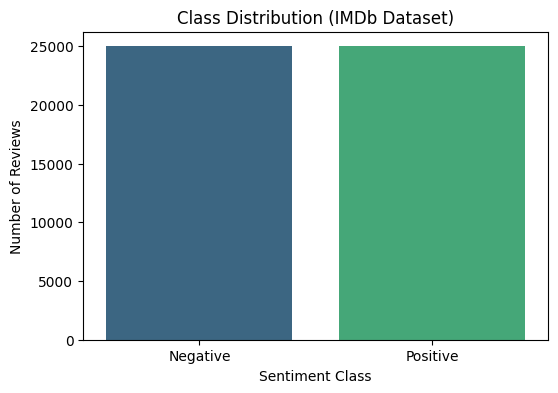

In [4]:
import tarfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/Colab_Notebooks/aclImdb_v1.tar.gz'
data = []

with tarfile.open(file_path, 'r:gz') as tar:
    for member in tar.getmembers():
        if member.isfile() and member.name.endswith('.txt'):
            parts = member.name.split('/')
            if len(parts) >= 4 and parts[1] in ['train', 'test'] and parts[2] in ['pos', 'neg']:
                label = 'Positive' if parts[2] == 'pos' else 'Negative'
                subset = parts[1]

                f = tar.extractfile(member)
                if f:
                    text = f.read().decode('utf-8', errors='ignore')
                    data.append({'subset': subset, 'label': label, 'text': text})

df = pd.DataFrame(data)

num_samples = len(df)
num_classes = df['label'].nunique()
missing_text = df['text'].isnull().sum()
missing_labels = df['label'].isnull().sum()
duplicates = df.duplicated(subset=['text']).sum()

df['doc_length'] = df['text'].apply(lambda x: len(x.split()))
min_len = df['doc_length'].min()
max_len = df['doc_length'].max()
mean_len = df['doc_length'].mean()

print("\n" + "="*50)
print(f"Số samples: {num_samples}")
print(f"Số classes: {num_classes} ({df['label'].unique()})")
print(f"Missing text (NaN): {missing_text}")
print(f"Missing labels (NaN): {missing_labels}")
print(f"Duplicate documents: {duplicates}")
print(f"Document length (words): Min={min_len}, Max={max_len}, Mean={mean_len:.2f}")
print("="*50)

class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100

print("\n--- BẢNG PHÂN PHỐI CLASS ---")
print(f"{'Class':<15} | {'Count':<10} | {'Percentage (%)':<15}")
print("-" * 45)
for cls in class_counts.index:
    print(f"{cls:<15} | {class_counts[cls]:<10} | {class_percentages[cls]:.2f}%")

plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Class Distribution (IMDb Dataset)')
plt.xlabel('Sentiment Class')
plt.ylabel('Number of Reviews')
plt.show()

**Dataset có imbalance (mất cân bằng) không?**

Dataset này hoàn toàn cân bằng (Perfectly Balanced).
Tổng số 50.000 mẫu được chia đều tuyệt đối: 25.000 mẫu cho lớp Positive (50%) và 25.000 mẫu cho lớp Negative (50%).

# 12. Data leakage

**Vì sao việc "Fit TF-IDF trên toàn bộ dataset trước khi split" lại là Data Leakage?**

- Vocabulary Leakage: Khi dùng fit trên toàn bộ dataset, tập từ vựng của TF-IDF sẽ bao gồm cả những từ độc quyền chỉ xuất hiện trong tập Validation/Test. Trong thực tế, dữ liệu tương lai là unseen data, mô hình không thể biết trước những từ mới này. Việc khai báo sẵn feature columns cho chúng là một dạng ăn gian.
- Rò rỉ đặc trưng thống kê: Trọng số IDF được tính toán dựa trên tổng số văn bản ($N$) và số văn bản chứa một từ cụ thể ($df$). Nếu ta tính IDF trên toàn bộ dataset, trọng số TF-IDF của các tài liệu trong tập Train đã bị "nhiễm" thông tin tần suất phân bố từ tập Test. Nghĩa là tập Train đang được biểu diễn dựa trên sự hiểu biết về tập Test.

# 13. Core implementation

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

train_df = df[df['subset'] == 'train'].copy()
test_df = df[df['subset'] == 'test'].copy()

train_y = (train_df['label'] == 'Positive').astype(int)
test_y = (test_df['label'] == 'Positive').astype(int)

tfidf = TfidfVectorizer(max_features=10000, stop_words='english')

train_X = tfidf.fit_transform(train_df['text'])

test_X = tfidf.transform(test_df['text'])

print(f"Kích thước ma trận Train: {train_X.shape}")
print(f"Kích thước ma trận Test : {test_X.shape}")

model_lr = LogisticRegression(max_iter=500, random_state=42)
model_lr.fit(train_X, train_y)

print("Đang dự đoán trên tập Test...\n")
pred_y = model_lr.predict(test_X)

print("="*45)
print(f"KẾT QUẢ ĐÁNH GIÁ TF-IDF + LOGISTIC REGRESSION")
print("="*45)
print(f"Accuracy: {accuracy_score(test_y, pred_y):.4f}\n")
print("Classification Report:")
print(classification_report(test_y, pred_y, target_names=['Negative (0)', 'Positive (1)']))

Kích thước ma trận Train: (25000, 10000)
Kích thước ma trận Test : (25000, 10000)
Đang dự đoán trên tập Test...

KẾT QUẢ ĐÁNH GIÁ TF-IDF + LOGISTIC REGRESSION
Accuracy: 0.8800

Classification Report:
              precision    recall  f1-score   support

Negative (0)       0.88      0.88      0.88     12500
Positive (1)       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



# 14. Experiment 2 — Baseline

In [7]:
import time
from sklearn.metrics import precision_recall_fscore_support

start_time = time.time()
model_lr = LogisticRegression(max_iter=500, random_state=42)
model_lr.fit(train_X, train_y)
train_time = time.time() - start_time

pred_y = model_lr.predict(test_X)

precision, recall, f1, _ = precision_recall_fscore_support(test_y, pred_y, average='macro')
vocab_size = len(tfidf.vocabulary_)
accuracy = accuracy_score(test_y, pred_y)

print(f"Training time   : {train_time:.2f} giây")
print(f"Vocabulary size : {vocab_size} từ")
print(f"Accuracy        : {accuracy:.4f}")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1 Score        : {f1:.4f}")

Training time   : 0.82 giây
Vocabulary size : 10000 từ
Accuracy        : 0.8800
Precision       : 0.8800
Recall          : 0.8800
F1 Score        : 0.8800


# 15. Experiment 3 — Representation comparison

In [9]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.6 MB/s eta 0:00:00


In [11]:
import numpy as np
from gensim.models import Word2Vec
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

#TF-IDF + Linear SVM
svm_model = LinearSVC(random_state=42, dual=False)
svm_model.fit(train_X, train_y)
pred_y_svm = svm_model.predict(test_X)
acc_svm = accuracy_score(test_y, pred_y_svm)
p_svm, r_svm, f1_svm, _ = precision_recall_fscore_support(test_y, pred_y_svm, average='macro')

#Average Word2Vec + Logistic Regression
train_tokens = [text.lower().split() for text in train_df['text']]
test_tokens = [text.lower().split() for text in test_df['text']]

w2v_model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=2, workers=4)

def document_vector(word2vec_model, doc_tokens):
    doc_vecs = [word2vec_model.wv[word] for word in doc_tokens if word in word2vec_model.wv]
    if len(doc_vecs) > 0:
        return np.mean(doc_vecs, axis=0)
    else:
        return np.zeros(word2vec_model.vector_size)

train_X_w2v = np.array([document_vector(w2v_model, tokens) for tokens in train_tokens])
test_X_w2v = np.array([document_vector(w2v_model, tokens) for tokens in test_tokens])

lr_w2v = LogisticRegression(max_iter=1000, random_state=42)
lr_w2v.fit(train_X_w2v, train_y)
pred_y_w2v = lr_w2v.predict(test_X_w2v)
acc_w2v = accuracy_score(test_y, pred_y_w2v)
p_w2v, r_w2v, f1_w2v, _ = precision_recall_fscore_support(test_y, pred_y_w2v, average='macro')


TF-IDF + Linear SVM       | Acc: 0.8601 | P: 0.8603 | R: 0.8601 | F1: 0.8601
Avg Word2Vec + LogReg     | Acc: 0.7788 | P: 0.7789 | R: 0.7788 | F1: 0.7788


In [17]:
print(f"TF-IDF + Logistic Regression  | Acc: {accuracy:.4f}  | P: {precision:.4f}     | R: {recall:.4f} | F1: {f1:.4f}")
print(f"TF-IDF + Linear SVM           | Acc: {acc_svm:.4f}  | P: {p_svm:.4f}     | R: {r_svm:.4f} | F1: {f1_svm:.4f}")
print(f"Avg Word2Vec + LogReg         | Acc: {acc_w2v:.4f}  | P: {p_w2v:.4f}     | R: {r_w2v:.4f} | F1: {f1_w2v:.4f}")

TF-IDF + Logistic Regression  | Acc: 0.8800  | P: 0.8800     | R: 0.8800 | F1: 0.8800
TF-IDF + Linear SVM           | Acc: 0.8601  | P: 0.8603     | R: 0.8601 | F1: 0.8601
Avg Word2Vec + LogReg         | Acc: 0.7788  | P: 0.7789     | R: 0.7788 | F1: 0.7788


# 16. Câu hỏi quan trọng

Dựa trên kết quả thực nghiệm, TF-IDF (Accuracy 88.00%) vượt trội hoàn toàn so với Average Word2Vec (Accuracy 77.88%).

1. TF-IDF trên tập văn bản dài:

- Sparse & Lexical: TF-IDF tạo ra một ma trận thưa khổng lồ, tập trung vào việc khớp từ vựng. Các từ thông dụng bị triệt tiêu trọng số, trong khi các từ hiếm mang tính quyết định được đẩy lên cao.

- Giữ thông tin term & Phù hợp với từ khóa đặc trưng: Để phân loại cảm xúc review phim, ta thường chỉ cần một vài từ khóa có giá trị (masterpiece, terrible, boring, excellent). TF-IDF giữ lại nguyên vẹn và tách biệt các feature này. Nhờ đó, Logistic Regression rất dễ dàng gán trọng số lớn cho các cột feature này để chốt nhãn ngay lập tức mà không bị nhiễu bởi các đoạn kể lể nội dung phim.

2. Điểm yếu của Average Word2Vec trên văn bản dài:

- Averaging làm mất thông tin quan trọng: Word2Vec tạo ra các dense vector mang tính ngữ nghĩa. Tuy nhiên, khi áp dụng cho một bài review dài 200-300 từ, việc cộng trung bình tất cả các vector sẽ làm tín hiệu của 1-2 từ cảm xúc mạnh bị chìm vào hàng trăm từ trung lập (the, actor, scene, camera).

- Mất trật tự từ: Tương tự Bag-of-Words, Average Word2Vec cộng dồn vector nên không giữ được cấu trúc câu, làm mất đi sức mạnh của các từ phủ định.

# 17. Experiment 4 — Word order

**Average Word Embeddings có hiểu được vai trò của từ "not" không?**

Hoàn toàn KHÔNG.
- Bản chất của phép cộng tuyến tính thực chất là  mang vector tĩnh của từ "not" cộng dồn vào tổng số. Nó xem "not" như một từ vựng độc lập y hệt "movie" hay "good".
- Không có tính tương tác: Từ "not" trong ngữ pháp đóng vai trò là một toán tử bẻ lái ý nghĩa của từ đi liền sau nó "good". Nhưng phép cộng trung bình không hề có cơ chế gộp nhóm "not good".

# 18. Experiment 5 — n-gram features

In [18]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

#Unigram (1-gram)
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=5)
train_X_uni = tfidf_uni.fit_transform(train_df['text'])
test_X_uni = tfidf_uni.transform(test_df['text'])

start = time.time()
lr_uni = LogisticRegression(max_iter=1000, random_state=42)
lr_uni.fit(train_X_uni, train_y)
time_uni = time.time() - start
f1_uni = f1_score(test_y, lr_uni.predict(test_X_uni), average='macro')

#Unigram + Bigram (1-gram và 2-gram)
tfidf_bi = TfidfVectorizer(ngram_range=(1, 2), min_df=5)
train_X_bi = tfidf_bi.fit_transform(train_df['text'])
test_X_bi = tfidf_bi.transform(test_df['text'])

start = time.time()
lr_bi = LogisticRegression(max_iter=1000, random_state=42)
lr_bi.fit(train_X_bi, train_y)
time_bi = time.time() - start
f1_bi = f1_score(test_y, lr_bi.predict(test_X_bi), average='macro')

print("--- KẾT QUẢ EXPERIMENT 5 ---")
print(f"Unigram      | Vocab: {len(tfidf_uni.vocabulary_):,} | F1: {f1_uni:.4f} | Time: {time_uni:.2f}s")
print(f"Uni + Bigram | Vocab: {len(tfidf_bi.vocabulary_):,} | F1: {f1_bi:.4f} | Time: {time_bi:.2f}s")

--- KẾT QUẢ EXPERIMENT 5 ---
Unigram      | Vocab: 27,272 | F1: 0.8837 | Time: 3.38s
Uni + Bigram | Vocab: 156,821 | F1: 0.8930 | Time: 4.37s


1. Đang vector hóa văn bản (Unigram + Bigram)...
2. Đang huấn luyện Logistic Regression...
3. Đang dự đoán trên tập Test...

KẾT QUẢ ĐÁNH GIÁ (EVALUATION)
Accuracy : 0.8957
Precision: 0.8957
Recall   : 0.8957
F1 Score : 0.8957

4. Đang vẽ Confusion Matrix...


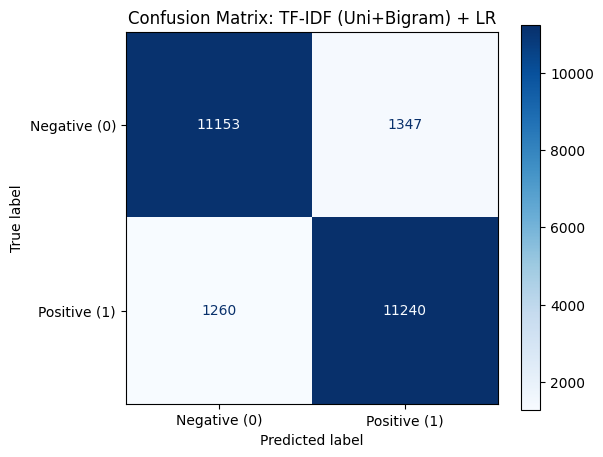

In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

print("1. Đang vector hóa văn bản (Unigram + Bigram)...")
tfidf_bi = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=25000)
train_X_bi = tfidf_bi.fit_transform(train_df['text'])
test_X_bi = tfidf_bi.transform(test_df['text'])

print("2. Đang huấn luyện Logistic Regression...")
lr_bi = LogisticRegression(max_iter=1000, random_state=42)
lr_bi.fit(train_X_bi, train_y)

print("3. Đang dự đoán trên tập Test...\n")
pred_y_bi = lr_bi.predict(test_X_bi)

acc = accuracy_score(test_y, pred_y_bi)
prec = precision_score(test_y, pred_y_bi, average='macro')
rec = recall_score(test_y, pred_y_bi, average='macro')
f1 = f1_score(test_y, pred_y_bi, average='macro')

print("="*30)
print("KẾT QUẢ ĐÁNH GIÁ (EVALUATION)")
print("="*30)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}\n")

print("4. Đang vẽ Confusion Matrix...")
cm = confusion_matrix(test_y, pred_y_bi)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title("Confusion Matrix: TF-IDF (Uni+Bigram) + LR")
plt.show()

**Vì sao bigram có thể giúp classification nhưng đồng thời làm feature space lớn hơn?**
- Nắm bắt ngữ cảnh cục bộ: Khắc phục triệt để điểm yếu của Unigram (Bag-of-Words). Bằng cách ghép 2 từ liên tiếp, Bigram giữ lại được trật tự từ cơ bản để xử lý từ phủ định và từ nhấn mạnh. Cụm "not good" hoặc "very bad" sẽ trở thành một feature độc lập mang cực cảm xúc rõ ràng, thay vì bị bóc tách thành "not", "good" gây nhầm lẫn cho classifier.
- Bùng nổ tổ hợp: Số lượng từ đơn (Unigram) bị giới hạn bởi vốn từ vựng tự nhiên. Nhưng số lượng Bigram là tổ hợp của các từ đi liền nhau. Nếu có $V$ từ vựng, trên lý thuyết có thể tạo ra $V^2$ bigrams. Dù trong thực tế không phải từ nào cũng ghép với nhau, số lượng cụm 2 từ (ví dụ: the movie, movie is, is good) vẫn khổng lồ và gấp hàng chục lần số lượng từ đơn, khiến ma trận TF-IDF trở nên cực kỳ thưa thớt, làm tăng mạnh thời gian huấn luyện.

# 22. Một experiment rất hay: Inspect model weights

In [21]:
import pandas as pd

feature_names = tfidf_bi.get_feature_names_out()

weights = lr_bi.coef_[0]

weights_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': weights
})

top_positive = weights_df.sort_values(by='Weight', ascending=False).head(10)
top_negative = weights_df.sort_values(by='Weight', ascending=True).head(10)

print("\n--- TOP POSITIVE FEATURES (w > 0) ---")
print(top_positive.to_string(index=False))

print("\n--- TOP NEGATIVE FEATURES (w < 0) ---")
print(top_negative.to_string(index=False))


--- TOP POSITIVE FEATURES (w > 0) ---
  Feature   Weight
    great 6.852725
excellent 5.318078
wonderful 4.405688
  perfect 4.324204
  amazing 3.750897
     best 3.674576
 the best 3.640208
      fun 3.470251
    today 3.341254
     love 3.335478

--- TOP NEGATIVE FEATURES (w < 0) ---
  Feature    Weight
      bad -7.564813
    worst -7.160161
    awful -5.885173
the worst -5.644414
   boring -5.464276
     poor -5.036641
    waste -4.899063
 terrible -4.348724
       no -4.252812
  nothing -4.167618


**Những feature này có thực sự có ý nghĩa đối với task không?**

Các feature được mô hình gán trọng số lớn nhất hoàn toàn có ý nghĩa và phản ánh chính xác bản chất của bài toán phân tích cảm xúc (Sentiment Analysis).
- Theo công thức $z = w^T x + b$, những từ mang hàm ý khen ngợi (ví dụ: excellent, great, wonderful) được học trọng số $w_i \gg 0$. Khi một bài review chứa các từ này, giá trị $z$ sẽ được đẩy lên rất cao, làm cho xác suất $\sigma(z)$ tiến gần về 1.
- Ngược lại, các từ mang ý nghĩa chê bai, thất vọng (ví dụ: bad, worst, awful) được gán trọng số âm rất sâu ($w_i \ll 0$). Sự xuất hiện của chúng kéo $z$ xuống mức âm, đẩy $\sigma(z)$ về 0.

# 23. Application

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

print("1. Đang khởi tạo dữ liệu huấn luyện (Customer Service Dataset)...")
train_texts = [
    # Intent: refund (Hoàn tiền)
    "I want my money back", "Please refund my order", "How do I get a refund?", "The product is broken, return my money",
    # Intent: cancel_order (Hủy đơn)
    "Cancel my purchase", "I want to cancel order #12345", "Stop the shipment, cancel it", "Mistake order, please cancel",
    # Intent: track_order (Theo dõi đơn hàng)
    "Where is my package?", "Track my shipment", "Has my order been shipped yet?", "When will my item arrive?",
    # Intent: payment_problem (Lỗi thanh toán)
    "My credit card was declined", "Payment failed", "Cannot process payment", "Why is my card not working?"
]

train_intents = [
    "refund", "refund", "refund", "refund",
    "cancel_order", "cancel_order", "cancel_order", "cancel_order",
    "track_order", "track_order", "track_order", "track_order",
    "payment_problem", "payment_problem", "payment_problem", "payment_problem"
]

print("2. Đang xây dựng Pipeline (TF-IDF + Logistic Regression)...")
intent_classifier = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('clf', LogisticRegression(random_state=42, C=1.0))
])

intent_classifier.fit(train_texts, train_intents)

print("3. Đang kiểm thử với các câu truy vấn thực tế (Unseen Data)...\n")
test_queries = [
    "Can you tell me where my package is right now?",
    "I accidentally bought this, cancel it please",
    "The transaction failed when I entered my visa",
    "Give me a refund, this is garbage"
]

# Dự đoán
predictions = intent_classifier.predict(test_queries)

print("--- KẾT QUẢ HỆ THỐNG PHÂN LOẠI Ý ĐỊNH (CHATBOT BOT) ---")
for query, intent in zip(test_queries, predictions):
    print(f"Khách hàng chat : '{query}'")
    print(f"=> Hệ thống bắt Intent : [{intent.upper()}]\n")

1. Đang khởi tạo dữ liệu huấn luyện (Customer Service Dataset)...
2. Đang xây dựng Pipeline (TF-IDF + Logistic Regression)...
3. Đang kiểm thử với các câu truy vấn thực tế (Unseen Data)...

--- KẾT QUẢ HỆ THỐNG PHÂN LOẠI Ý ĐỊNH (CHATBOT BOT) ---
Khách hàng chat : 'Can you tell me where my package is right now?'
=> Hệ thống bắt Intent : [TRACK_ORDER]

Khách hàng chat : 'I accidentally bought this, cancel it please'
=> Hệ thống bắt Intent : [CANCEL_ORDER]

Khách hàng chat : 'The transaction failed when I entered my visa'
=> Hệ thống bắt Intent : [PAYMENT_PROBLEM]

Khách hàng chat : 'Give me a refund, this is garbage'
=> Hệ thống bắt Intent : [REFUND]

